# SeizeIT2: Participant-Level Metadata Summary

**Purpose:** build one table per participant showing:
- participant details available in `participants.tsv`
- which wearable modalities have recording files
- number of signal recordings/files per modality
- number of annotation files
- optional recording-duration information if available from metadata

**No full dataset download is needed.** This notebook downloads only small metadata/index files. It does not download the raw EDF signal recordings.

Dataset: [OpenNeuro ds005873, version 1.1.0](https://openneuro.org/datasets/ds005873/versions/1.1.0)

> Important distinction: a recording file is not the same thing as an individual sample/reading. File counts are used as a practical inventory. The number of time samples requires reading the signal data or additional metadata.

## What was changed in this version (and why)

Fixes are marked `# FIX:` in the code.

**Errors that stopped the notebook from running**
1. **Section 1:** `data.nemar.org/.../v1.0.0` returned *HTTP 500*. It was also the old release: v1.1.0 *corrected the accelerometer data*. Metadata now comes from v1.1.0 (OpenNeuro's GitHub mirror, then OpenNeuro's S3 bucket as a backup).
2. **Steps 1–3:** `from config import *` raised *ModuleNotFoundError* because there is no `config.py`. Those lines are removed; the config cell's variables are used directly.
3. **Step 3:** `argparse` breaks in Jupyter/Colab (it reads the kernel's `-f` argument and exits). It is replaced by `run(split="cv")`.
4. **No local dataset:** Step 1 found 0 event files and crashed. The new **Step 0** clones the metadata and downloads each EDF from OpenNeuro when it is needed, then deletes it.
5. **Install cell:** adds `pyedflib` (not in Colab, so every recording failed in Step 2) and `xgboost`.

**Method changes needed to answer the research question**
6. **Seizure definition:** checked against `events.json`. Generalised (`sz_gen_*`) and unknown-onset (`sz_uo_*`) seizures are no longer targets. The `SEIZURE_DEFINITION` setting chooses *all focal except f2b* or *focal non-motor only*.
7. **EMG** is now loaded and featurised (20–100 Hz band-pass + 50 Hz notch; RMS, MAV, waveform length, zero crossings, band power, median frequency, burstiness).
8. **Sensor comparison:** XGBoost is trained separately on **ACC**, **ACC+GYR** and **ACC+GYR+EMG**, all on the same recordings.
9. **Leakage:** removed the per-participant z-score over the whole recording, which used future test data. Features are relative to a trailing 5-minute baseline only.
10. **Gaps:** smoothing restarts after gaps, and monitoring hours (the false-alarm denominator) are counted per contiguous segment.
11. **Per-sensor features:** the neck and chest SensorDots are no longer mixed into one magnitude. Recordings with 3–11 movement channels are logged rather than silently mis-featurised.
12. **New Steps 4–5:** participant-level bootstrap 95 % CIs, a paired sensor comparison, sensitivity by seizure type, and the two figures the rubric requires.


## 1. Load small metadata files

FIX: metadata now comes from OpenNeuro version 1.1.0 (its GitHub mirror, with OpenNeuro's S3 bucket as a backup). The NEMAR v1.0.0 endpoint was returning HTTP 500, and v1.0.0 holds the uncorrected accelerometer data.

In [ ]:
import json
import requests
import pandas as pd
from io import StringIO
from pathlib import Path
from collections import Counter, defaultdict
from IPython.display import display

# FIX: the old source (data.nemar.org/on005873/v1.0.0) returns HTTP 500, and v1.0.0 is also the
# release BEFORE the accelerometer data were corrected (see the dataset CHANGES file: 1.1.0 =
# "Corrected accelerometer data"). Use v1.1.0 sources instead, trying each until one works.
METADATA_SOURCES = [
    "https://raw.githubusercontent.com/OpenNeuroDatasets/ds005873/main",   # OpenNeuro's GitHub mirror (v1.1.0)
    "https://s3.amazonaws.com/openneuro.org/ds005873",                    # OpenNeuro's public S3 bucket
]
HEADERS = {"User-Agent": "SeizeIT2-metadata-summary/1.0"}


def get_text(url):
    response = requests.get(url, headers=HEADERS, timeout=60)
    response.raise_for_status()
    return response.text


def get_metadata_file(name):
    """Return the text of a top-level dataset file, trying each source in turn."""
    errors = []
    for base in METADATA_SOURCES:
        try:
            return get_text(f"{base}/{name}")
        except Exception as exc:
            errors.append(f"{base}: {exc}")
    raise RuntimeError(f"Could not download {name} from any source:\n  " + "\n  ".join(errors))


participants = pd.read_csv(StringIO(get_metadata_file("participants.tsv")), sep="\t")

try:
    participant_dictionary = json.loads(get_metadata_file("participants.json"))
except Exception as exc:
    participant_dictionary = {}
    print("Could not load participants.json:", exc)

try:
    dataset_description = json.loads(get_metadata_file("dataset_description.json"))
except Exception as exc:
    dataset_description = {}
    print("Could not load dataset_description.json:", exc)

print("Participant rows:", len(participants))
print("Participant metadata columns:", participants.columns.tolist())
print("Dataset name:", dataset_description.get("Name", "Not provided"))
display(participants.head())


Participant rows: 125
Participant metadata columns: ['participant_id', 'sex']
Dataset name: SeizeIT2


,participant_id,sex
0,sub-001,f
1,sub-002,m
2,sub-003,m
3,sub-004,m
4,sub-005,f


## 2. Understand what participant details mean

`participants.tsv` contains the participant-level variables that are actually published in the dataset. `participants.json` explains the meaning and categories of those columns. Do not assume age, diagnosis details, or other clinical characteristics are available unless they appear in the table.

In [ ]:
# Create a compact data dictionary for the participant metadata
dictionary_rows = []
for column in participants.columns:
    definition = participant_dictionary.get(column, {})
    dictionary_rows.append({
        "column": column,
        "description": definition.get("Description", "No description provided in participants.json"),
        "units": definition.get("Units", ""),
        "levels_or_categories": json.dumps(definition.get("Levels", {}), ensure_ascii=False)
    })

participant_data_dictionary = pd.DataFrame(dictionary_rows)
display(participant_data_dictionary)


,column,description,units,levels_or_categories
0,participant_id,No description provided in participants.json,,{}
1,sex,sex of the participant as reported by the part...,,"{""m"": ""male"", ""f"": ""female""}"


## 3. Get a file index without downloading signal files

The GitHub repository mirrors the BIDS directory structure. Its recursive file index contains paths and filenames, not the raw signal contents. We use that index to count files for each participant and modality.

If the GitHub API is rate-limited or unavailable, the cell will show an error rather than silently producing incorrect counts.

In [ ]:
tree_url = "https://api.github.com/repos/OpenNeuroDatasets/ds005873/git/trees/main?recursive=1"
response = requests.get(tree_url, headers=HEADERS, timeout=90)
response.raise_for_status()
tree_data = response.json()

if tree_data.get("truncated"):
    print("Warning: GitHub returned a truncated file index; counts may be incomplete.")

file_paths = [
    item["path"] for item in tree_data.get("tree", [])
    if item.get("type") == "blob"
]

print("Paths in file index:", len(file_paths))
print("Example paths:")
for p in file_paths[:15]:
    print(" ", p)


Paths in file index: 24877
Example paths:
  .bidsignore
  .datalad/config
  .gitattributes
  CHANGES
  README
  dataset_description.json
  events.json
  participants.json
  participants.tsv
  sub-001/ses-01/ecg/sub-001_ses-01_task-szMonitoring_run-01_ecg.edf
  sub-001/ses-01/ecg/sub-001_ses-01_task-szMonitoring_run-01_ecg.json
  sub-001/ses-01/ecg/sub-001_ses-01_task-szMonitoring_run-02_ecg.edf
  sub-001/ses-01/ecg/sub-001_ses-01_task-szMonitoring_run-02_ecg.json
  sub-001/ses-01/ecg/sub-001_ses-01_task-szMonitoring_run-03_ecg.edf
  sub-001/ses-01/ecg/sub-001_ses-01_task-szMonitoring_run-03_ecg.json


## 4. Count files per participant and modality

The BIDS folder names identify the participant (`sub-xxx`) and modality (`eeg`, `ecg`, `emg`, or `mov`). We count:
- **signal files**: `.edf` files, which hold the recorded signals
- **event annotation files**: `*_events.tsv`
- **all files**: all indexed files under the participant folder and modality

These are file counts, not sample counts. One EDF can contain many thousands or millions of time samples.

In [ ]:
MODALITIES = {"eeg", "ecg", "emg", "mov"}
counts = defaultdict(Counter)
duration_rows = []

for path in file_paths:
    parts = path.split("/")
    participant_id = next((part for part in parts if part.startswith("sub-")), None)
    if participant_id is None:
        continue

    modality = next((part for part in parts if part in MODALITIES), None)
    if modality is None:
        # Keep participant-level files too, but do not assign them to a modality.
        modality = "participant-level"

    name = parts[-1].lower()
    counts[participant_id]["all_files"] += 1
    counts[participant_id][f"{modality}_files"] += 1

    if name.endswith(".edf"):
        counts[participant_id]["signal_edf_files"] += 1
        counts[participant_id][f"{modality}_edf_files"] += 1

    if name.endswith("_events.tsv"):
        counts[participant_id]["event_annotation_files"] += 1

    if name.endswith("_scans.tsv"):
        counts[participant_id]["scans_metadata_files"] += 1

count_table = pd.DataFrame.from_dict(counts, orient="index").fillna(0).astype(int)
count_table.index.name = "participant_id"
count_table = count_table.reset_index()

# Ensure all expected count columns exist even if a category has zero files.
expected_columns = [
    "all_files", "signal_edf_files", "event_annotation_files",
    "scans_metadata_files",
    "eeg_files", "eeg_edf_files", "ecg_files", "ecg_edf_files",
    "emg_files", "emg_edf_files", "mov_files", "mov_edf_files"
]
for col in expected_columns:
    if col not in count_table.columns:
        count_table[col] = 0

display(count_table.head())
print("Participants represented in file index:", count_table["participant_id"].nunique())


,participant_id,all_files,ecg_files,signal_edf_files,ecg_edf_files,eeg_files,eeg_edf_files,event_annotation_files,emg_files,emg_edf_files,mov_files,mov_edf_files,scans_metadata_files
0,sub-001,81,18,36,9,27,9,9,18,9,18,9,0
1,sub-002,108,24,48,12,36,12,12,24,12,24,12,0
2,sub-003,90,20,40,10,30,10,10,20,10,20,10,0
3,sub-004,9,2,4,1,3,1,1,2,1,2,1,0
4,sub-005,234,52,104,26,78,26,26,52,26,52,26,0


Participants represented in file index: 125


## 5. Combine participant details and recording counts

This is the main output table. It joins the participant-level information to the per-participant file inventory.

In [ ]:
# Normalize participant IDs in case the table uses a BIDS-style participant_id column.
id_col = next((c for c in participants.columns if c.lower() in {"participant_id", "participant", "subject_id", "sub"}), None)

if id_col is None:
    raise ValueError(
        "Could not identify the participant ID column in participants.tsv. "
        "Inspect participants.columns and set id_col manually."
    )

participant_details = participants.copy()
participant_details["participant_id"] = participant_details[id_col].astype(str)
participant_details["participant_id"] = participant_details["participant_id"].apply(
    lambda x: x if x.startswith("sub-") else f"sub-{x}"
)

participant_summary = participant_details.merge(
    count_table, on="participant_id", how="left"
)

count_cols = [c for c in count_table.columns if c != "participant_id"]
participant_summary[count_cols] = participant_summary[count_cols].fillna(0).astype(int)

# Add readable modality-presence indicators.
for modality in ["eeg", "ecg", "emg", "mov"]:
    file_col = f"{modality}_edf_files"
    participant_summary[f"has_{modality}_recording"] = participant_summary[file_col] > 0

display(participant_summary)


,participant_id,sex,all_files,ecg_files,signal_edf_files,ecg_edf_files,eeg_files,eeg_edf_files,event_annotation_files,emg_files,emg_edf_files,mov_files,mov_edf_files,scans_metadata_files,has_eeg_recording,has_ecg_recording,has_emg_recording,has_mov_recording
0,sub-001,f,81,18,36,9,27,9,9,18,9,18,9,0,True,True,True,True
1,sub-002,m,108,24,48,12,36,12,12,24,12,24,12,0,True,True,True,True
2,sub-003,m,90,20,40,10,30,10,10,20,10,20,10,0,True,True,True,True
3,sub-004,m,9,2,4,1,3,1,1,2,1,2,1,0,True,True,True,True
4,sub-005,f,234,52,104,26,78,26,26,52,26,52,26,0,True,True,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
120,sub-121,m,777,222,333,111,333,111,111,222,111,0,0,0,True,True,True,False
121,sub-122,m,630,140,280,70,210,70,70,140,70,140,70,0,True,True,True,True
122,sub-123,m,763,170,339,85,255,85,85,170,85,168,84,0,True,True,True,True
123,sub-124,m,756,168,336,84,252,84,84,168,84,168,84,0,True,True,True,True


## 6. Dataset-level summary table

This second table summarizes the whole dataset inventory to make it easier to report the available data types.

In [ ]:
dataset_summary = pd.DataFrame([
    {"Metric": "Participants in participants.tsv", "Value": len(participants)},
    {"Metric": "Participants with files in index", "Value": count_table["participant_id"].nunique()},
    {"Metric": "Total indexed EDF signal files", "Value": int(count_table["signal_edf_files"].sum())},
    {"Metric": "Total event annotation files", "Value": int(count_table["event_annotation_files"].sum())},
])

for modality in ["eeg", "ecg", "emg", "mov"]:
    dataset_summary.loc[len(dataset_summary)] = {
        "Metric": f"EDF signal files in {modality.upper()} folder",
        "Value": int(count_table.get(f"{modality}_edf_files", pd.Series(dtype=int)).sum())
    }

display(dataset_summary)


,Metric,Value
0,Participants in participants.tsv,125
1,Participants with files in index,125
2,Total indexed EDF signal files,11009
3,Total event annotation files,2850
4,EDF signal files in EEG folder,2850
5,EDF signal files in ECG folder,2804
6,EDF signal files in EMG folder,2804
7,EDF signal files in MOV folder,2551


## 7. Export the tables

The CSVs can be opened in Excel or included in your project workflow.

In [ ]:
OUTPUT_DIR = Path("seizeit2_metadata_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

participants.to_csv(OUTPUT_DIR / "participants_original.tsv", sep="\t", index=False)
participant_data_dictionary.to_csv(OUTPUT_DIR / "participant_metadata_dictionary.csv", index=False)
count_table.to_csv(OUTPUT_DIR / "recording_file_counts_by_participant.csv", index=False)
participant_summary.to_csv(OUTPUT_DIR / "participant_metadata_and_recording_counts.csv", index=False)
dataset_summary.to_csv(OUTPUT_DIR / "dataset_level_summary.csv", index=False)

print("Saved files:")
for path in sorted(OUTPUT_DIR.iterdir()):
    print("-", path)


Saved files:
- seizeit2_metadata_outputs/dataset_level_summary.csv
- seizeit2_metadata_outputs/participant_metadata_and_recording_counts.csv
- seizeit2_metadata_outputs/participant_metadata_dictionary.csv
- seizeit2_metadata_outputs/participants_original.tsv
- seizeit2_metadata_outputs/recording_file_counts_by_participant.csv


## Interpretation notes

- `participants.tsv` gives participant-level details that are explicitly shared in the dataset. The dictionary table explains the available fields.
- `*_edf_files` counts signal files. It does **not** count individual time samples.
- The four modality folders correspond to behind-the-ear EEG, ECG, EMG, and movement data. Movement data include accelerometer (ACC) and gyroscope (GYR) signals.
- Annotation-file counts are not the same as seizure counts. To count seizures, the event TSVs must be read and the event-label conventions checked.
- The file index is taken from the public GitHub mirror. If exact version matching is essential, compare its version/commit with OpenNeuro version 1.1.0 before presenting the counts.
- The dataset has 125 participants overall. The published study describes approximately 11,640 hours of wearable recordings and 886 focal seizures; these are published dataset-level figures, not values calculated by this notebook.

Dataset: Bhagubai et al., *SeizeIT2: Wearable Dataset Of Patients With Focal Epilepsy*. [OpenNeuro ds005873 v1.1.0](https://openneuro.org/datasets/ds005873/versions/1.1.0).

# Part B: Seizure-detection pipeline (ACC vs ACC+GYR vs ACC+GYR+EMG)

Run the cells below **in order, from the install cell onward**. On Colab:

* **Google Drive:** the settings cell connects to your Google Drive (allow the pop-up). All outputs go to `MyDrive/bmen600_outputs`, so a disconnect does not lose finished work.
* **Quick test first:** set `MAX_SUBJECTS = 10` in the settings cell. This takes a few minutes and checks that everything runs.
* **Full analysis:** set `MAX_SUBJECTS = None`. Step 2 downloads about 45 GB, processing `N_WORKERS` recordings at a time and deleting each file after use. It prints the estimated time left.
* **If Colab disconnects:** run the cells again from the install cell. Recordings already saved in Drive are skipped, so it carries on where it stopped.

In [ ]:
# Install the packages Colab does not have (pyedflib reads the EDF signal files)
%pip install -q pyedflib xgboost


In [ ]:
"""Shared settings for the SeizeIT2 ACC / GYR / EMG seizure-detection pipeline.

FIX: this cell now holds every setting. The later cells no longer use `from config import *`
(there is no config.py file, so that line raised ModuleNotFoundError); they simply use the
variables defined here, so run this cell first.
"""
import os
from pathlib import Path

DATA_ROOT = Path(os.environ.get("SZ_DATA", "ds005873"))   # local copy of the dataset (created by the next cell)

# FIX: on Colab, results are saved to Google Drive automatically, so a disconnect does not lose work.
# Colab deletes everything outside Drive when the runtime disconnects. Allow the Drive pop-up when it appears.
SAVE_TO_DRIVE = True
DRIVE_OUT = "/content/drive/MyDrive/bmen600_outputs"
try:
    from google.colab import drive as _drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if "SZ_OUT" in os.environ:
    OUT = Path(os.environ["SZ_OUT"])
elif IN_COLAB and SAVE_TO_DRIVE:
    _drive.mount("/content/drive")
    OUT = Path(DRIVE_OUT)
else:
    OUT = Path("outputs")
print("outputs will be saved in:", OUT.resolve())
FEATURE_DIR = OUT / "features"
RESULT_DIR = OUT / "results"
FIG_DIR = OUT / "figures"
for d in (OUT, FEATURE_DIR, RESULT_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

# --- data download -------------------------------------------------------------
# The full movement + EMG data are about 45 GB. Edf files are downloaded one recording at a time,
# processed and then deleted (KEEP_EDF = False), so disk use stays small.
# Set MAX_SUBJECTS to a small number (e.g. 10) for a quick test run; None = all participants.
MAX_SUBJECTS = None
KEEP_EDF = False
N_WORKERS = 4      # recordings downloaded + processed at the same time in Step 2 (lower to 2 if Colab runs out of RAM)
EDF_SOURCE = "https://s3.amazonaws.com/openneuro.org/ds005873"   # OpenNeuro public bucket (v1.1.0)

# --- signal processing ---------------------------------------------------------
FS = 25                    # ACC/GYR sampling rate (verified: every *_mov.json says 25 Hz) -> Nyquist 12.5 Hz
BAND_HZ = (0.5, 10.0)      # band-pass must stay below Nyquist (12.5 Hz)
EMG_FS = 256               # EMG sampling rate (verified: every *_emg.json says 256 Hz) -> Nyquist 128 Hz
EMG_BAND_HZ = (20.0, 100.0)
EMG_NOTCH_HZ = 50.0        # European power line (recordings are from European epilepsy units)
WIN_S, STEP_S = 10, 5      # window length / step in seconds (many seizures are short)
BASELINE_WIN = 60          # trailing baseline = 60 windows = 5 min at a 5 s step

# --- labelling -----------------------------------------------------------------
MIN_OVERLAP_S = 3          # window is "seizure" if it overlaps a seizure by >= this
BUFFER_S = 30              # windows this close to a seizure edge are left out of TRAINING

# FIX: seizure labels verified against events.json (v1.1.0). Every seizure label starts with "sz".
#   sz_foc_*      focal seizures (sz_foc_*_nm* = non-motor, sz_foc_*_m* = motor)
#   sz_foc_f2b    focal to bilateral tonic-clonic  -> convulsive, never a target
#   sz_gen_*      generalised onset                -> not focal, never a target
#   sz_uo_*       unknown onset                    -> not confirmed focal, never a target
# Old code: every "sz" label except f2b was a target, which also counted generalised and
# unknown-onset seizures. Choose the target definition here:
#   "focal_all"      every focal seizure except f2b (822 seizures / 106 participants)
#   "focal_nonmotor" only focal NON-motor seizures   (323 seizures / 51 participants)
SEIZURE_DEFINITION = "focal_all"


def is_target_seizure(event_type: str) -> bool:
    t = str(event_type).lower()
    if not t.startswith("sz_foc") or t == "sz_foc_f2b":
        return False
    if SEIZURE_DEFINITION == "focal_nonmotor":
        return "_nm" in t
    return True
# Seizures that are not targets are still seizures: windows around them are dropped, so they are
# never labelled as background.

# --- sensor comparison (the research question) ---------------------------------
# FIX: the old code fed every feature to one XGBoost model, so it could not show what each sensor
# adds. Each entry below is trained and evaluated separately on the SAME recordings.
FEATURE_SETS = {
    "ACC":         ["acc"],
    "ACC+GYR":     ["acc", "gyr"],
    "ACC+GYR+EMG": ["acc", "gyr", "emg"],
}
REQUIRE_ALL_SENSORS = True   # keep only recordings that have ACC, GYR and EMG, so the comparison is fair
SENSOR_FLAGS = ["has_acc", "has_gyr", "has_emg"]

# --- event-level scoring (SzCORE-style tolerances) ------------------------------
PRE_TOL_S, POST_TOL_S, MERGE_S = 30, 60, 90
FA_TARGETS = [1, 5, 10]    # false alarms per 24 h we tune the alarm rule for
SMOOTH_N = 3               # moving-average length (windows) applied to scores
K_GRID = [1, 2, 3, 4]      # consecutive windows needed to fire an alarm

# --- splits / statistics --------------------------------------------------------
OFFICIAL_TRAIN_MAX_SUB = 96   # SeizeIT2 suggested split: sub-001..096 train, 097..125 validation
N_FOLDS = 5
NEG_RATIO = 10                # background windows kept per seizure window when training
N_BOOT = 2000                 # participant-level bootstrap resamples for confidence intervals
SEED = 0


Mounted at /content/drive
outputs will be saved in: /content/drive/MyDrive/bmen600_outputs


In [ ]:
"""Step 0: get the dataset metadata locally, and a helper that downloads EDF signal files on demand.

FIX: the old pipeline assumed a full local copy in ./ds005873 already existed. Without it,
Step 1 found 0 event files and crashed on szs["eventType"] (KeyError).

The GitHub mirror holds every *_events.tsv and *.json file (small, about 25k files). The EDF signal
files in the mirror are only git-annex placeholders, so the real EDFs come from OpenNeuro's S3 bucket.
"""
import shutil
import subprocess
import urllib.request

if not (DATA_ROOT / "participants.tsv").exists():
    print("Cloning the dataset metadata (events + sidecars, no signal data)...")
    subprocess.run(["git", "clone", "--depth", "1",
                    "https://github.com/OpenNeuroDatasets/ds005873", str(DATA_ROOT)],
                   check=True, env={**os.environ, "GIT_LFS_SKIP_SMUDGE": "1"})
print("events files available:", len(list(DATA_ROOT.glob("sub-*/ses-*/eeg/*_events.tsv"))))


def fetch_edf(path):
    """Return a local path to a real EDF file, downloading it from OpenNeuro if needed."""
    path = Path(path)
    if path.is_file() and path.stat().st_size > 1024:      # a real file (not a dangling annex symlink)
        return path
    if path.is_symlink() or path.exists():
        path.unlink()                                         # remove the git-annex placeholder
    rel = path.relative_to(DATA_ROOT).as_posix()
    tmp = path.with_suffix(".part")
    with urllib.request.urlopen(f"{EDF_SOURCE}/{rel}", timeout=300) as r, open(tmp, "wb") as f:
        shutil.copyfileobj(r, f, length=1 << 20)
    tmp.rename(path)
    return path


def release_edf(path):
    """Delete a downloaded EDF after processing, unless KEEP_EDF is True."""
    if not KEEP_EDF:
        Path(path).unlink(missing_ok=True)


events files available: 2850


In [ ]:
"""Step 1: build recordings.csv and seizures.csv from the BIDS *_events.tsv files.

Only the small events.tsv files (eeg folders) and the mov/emg sidecars are needed.
FIX: removed `from config import *` (settings come from the config cell above).
"""
import re
import numpy as np
import pandas as pd
import json
import re
import numpy as np


def tok(name, key):
    m = re.search(rf"{key}-([A-Za-z0-9]+)", name)
    return m.group(1) if m else None


def match_edf(folder, sub, ses, run):
    """Find the EDF in `folder` that belongs to the same sub/ses/run."""
    if not folder.exists():
        return ""
    for f in sorted(folder.glob("*.edf")):
        if (tok(f.name, "sub"), tok(f.name, "ses"), tok(f.name, "run")) == (sub, ses, run):
            return str(f)
    return ""


def mov_channel_count(mov_file):
    """MOVChannelCount from the JSON sidecar (12 = ACC + GYR from both sensors)."""
    side = Path(mov_file).with_suffix(".json") if mov_file else None
    if side is None or not side.exists():
        return 0
    return int(json.loads(side.read_text()).get("MOVChannelCount", 0))


rec_rows, sz_rows = [], []
event_files = sorted(DATA_ROOT.glob("sub-*/ses-*/eeg/*_events.tsv"))
if MAX_SUBJECTS:
    keep_subs = sorted({tok(e.name, "sub") for e in event_files})[:MAX_SUBJECTS]
    event_files = [e for e in event_files if tok(e.name, "sub") in keep_subs]
print("event files found:", len(event_files))
if not event_files:
    raise FileNotFoundError(f"No *_events.tsv files under {DATA_ROOT.resolve()} - run the download cell first.")

for ev in event_files:
    sub, ses, run = tok(ev.name, "sub"), tok(ev.name, "ses"), tok(ev.name, "run")
    rec = f"sub-{sub}_ses-{ses}_run-{run}"
    df = pd.read_csv(ev, sep="\t")
    if ev is event_files[0]:
        print("events.tsv columns:", df.columns.tolist())

    dur = np.nan
    if "recordingDuration" in df.columns:
        vals = pd.to_numeric(df["recordingDuration"], errors="coerce").dropna()
        dur = float(vals.iloc[0]) if len(vals) else np.nan

    mov_file = match_edf(ev.parent.parent / "mov", sub, ses, run)
    rec_rows.append(dict(rec=rec, subject=sub, session=ses, run=run,
                         mov_file=mov_file,
                         emg_file=match_edf(ev.parent.parent / "emg", sub, ses, run),
                         mov_channels=mov_channel_count(mov_file),
                         recording_duration_s=dur))

    etype = df["eventType"].astype(str)
    for _, r in df[etype.str.lower().str.startswith("sz")].iterrows():
        sz_rows.append(dict(rec=rec, subject=sub, onset=float(r["onset"]),
                            duration=float(r["duration"]), eventType=str(r["eventType"]),
                            vigilance=r.get("vigilance", np.nan)))
        # (the old code also stored "confidence"; that column does not exist in the events files)

recs = pd.DataFrame(rec_rows)
szs = pd.DataFrame(sz_rows, columns=["rec", "subject", "onset", "duration", "eventType", "vigilance"])
szs["include"] = szs["eventType"].map(is_target_seizure).astype(bool)

recs.to_csv(OUT / "recordings.csv", index=False)
szs.to_csv(OUT / "seizures.csv", index=False)

print("\nrecordings:", len(recs), "| without mov file:", int((recs.mov_file == "").sum()),
      "| without emg file:", int((recs.emg_file == "").sum()))
print(f"seizures total: {len(szs)} | target seizures ({SEIZURE_DEFINITION}): {int(szs.include.sum())}")
print("\nseizure eventType counts (include = counted as a target seizure):")
print(szs.groupby(["eventType", "include"]).size().to_string())
full = set(recs.loc[(recs.mov_file != "") & (recs.emg_file != "") & (recs.mov_channels == 12), "rec"])
print("\ntarget seizures in recordings with all 12 movement channels + EMG:",
      int((szs.include & szs.rec.isin(full)).sum()))


event files found: 2850
events.tsv columns: ['onset', 'duration', 'eventType', 'lateralization', 'localization', 'vigilance', 'confidence', 'channels', 'dateTime', 'recordingDuration']

recordings: 2850 | without mov file: 299 | without emg file: 46
seizures total: 883 | target seizures (focal_all): 822

seizure eventType counts (include = counted as a target seizure):
eventType                 include
sz_foc_a_m_automatisms    True         4
sz_foc_a_m_hyperkinetic   True       158
sz_foc_a_nm               True        66
sz_foc_a_nm_behavior      True        38
sz_foc_a_um               True        50
sz_foc_f2b                False       55
sz_foc_ia                 True        35
sz_foc_ia_m_automatisms   True        62
sz_foc_ia_m_clonic        True         1
sz_foc_ia_m_hyperkinetic  True       100
sz_foc_ia_m_tonic         True        24
sz_foc_ia_nm              True       160
sz_foc_ia_nm_behavior     True         2
sz_foc_ia_um              True         7
sz_foc_ua_m         

In [ ]:
"""Step 2: filter ACC/GYR and EMG, cut windows, extract features, attach labels.

Writes one outputs/features/<rec>.pkl per recording plus preprocessing_log.csv.

FIXES in this cell
- removed `from config import *`; `if __name__ == "__main__":` replaced by a function call
- EMG is now loaded, filtered (20-100 Hz band-pass + 50 Hz notch) and turned into features
- movement channels are grouped per physical sensor (neck and chest SensorDots) before computing
  the magnitude. The old code put all 6 ACC axes of BOTH sensors into one magnitude.
- recordings with 3-11 movement channels (about 240 files) no longer silently produce wrong features;
  each recording logs which sensors it actually has (has_acc / has_gyr / has_emg)
- EDF type and signal length are logged, so discontinuous (EDF+D) files can be checked
- missing samples are no longer replaced by 0 before filtering (that creates artificial steps);
  they are interpolated, and windows with >20 % missing samples are still marked bad
- already-processed recordings are skipped, so the cell can be re-run after a Colab disconnect
- N_WORKERS recordings are downloaded and processed at the same time (prints progress + time left)
"""
import json
import re
import time
import numpy as np
import pandas as pd
from numpy.lib.stride_tricks import sliding_window_view
from scipy.signal import butter, sosfiltfilt, iirnotch, filtfilt, resample_poly, welch

WIN, STEP = WIN_S * FS, STEP_S * FS
EMG_WIN, EMG_STEP = WIN_S * EMG_FS, STEP_S * EMG_FS
BANDS = [(0.5, 2), (2, 5), (5, 10)]


def edf_variant(path):
    """'EDF+C' (continuous), 'EDF+D' (discontinuous) or 'EDF', read from the file header."""
    try:
        with open(path, "rb") as f:
            reserved = f.read(256)[192:236].decode("ascii", "ignore").strip()
        return reserved or "EDF"
    except OSError:
        return "unknown"


def read_edf(path):
    import pyedflib
    f = pyedflib.EdfReader(str(path))
    labels = f.getSignalLabels()
    fs = [f.getSampleFrequency(i) for i in range(f.signals_in_file)]
    sig = [f.readSignal(i) for i in range(f.signals_in_file)]
    f.close()
    return labels, fs, sig


def fill_gaps(x):
    """Linear interpolation over NaNs (instead of setting them to 0)."""
    x = np.asarray(x, float)
    bad = ~np.isfinite(x)
    if bad.all():
        return np.zeros_like(x)
    if bad.any():
        idx = np.arange(len(x))
        x = x.copy()
        x[bad] = np.interp(idx[bad], idx[~bad], x[~bad])
    return x


def to_rate(s, f_in, f_out):
    """Resample only if needed, using the exact rational ratio (not rounded integers)."""
    if abs(f_in - f_out) < 1e-6:
        return np.asarray(s, float)
    from fractions import Fraction
    fr = Fraction(f_out / f_in).limit_denominator(1000)
    return resample_poly(np.asarray(s, float), fr.numerator, fr.denominator)


def sensor_key(label):
    """('acc' | 'gyr' | None, sensor name with the axis letter removed)."""
    lab = label.lower()
    group = "acc" if "acc" in lab else "gyr" if "gyr" in lab else None
    # SeizeIT2 labels look like "EEG SD ACC X" (neck) / "ECGEMG SD GYR A" (chest):
    # ACC axes are X/Y/Z and GYR axes are A/B/C, so drop that final axis letter to get the sensor name.
    key = re.sub(r"(?<![a-z])[xyzabc](?![a-z])", "", lab)
    key = re.sub(r"[\s_\-\.]+", " ", key).strip()
    return group, key


def split_groups(labels, fs, sig):
    """Return {'acc': [[ax1, ax2, ax3], ...one list per complete sensor], 'gyr': [...]} resampled to FS.

    A sensor with a missing axis is dropped rather than mixed with the other sensor's axes.
    If a modality ends up with no complete sensor, it counts as unavailable (has_acc / has_gyr = 0)
    and the recording is left out of the three-way comparison."""
    per_sensor = {"acc": {}, "gyr": {}}
    for lab, f_, s in zip(labels, fs, sig):
        g, key = sensor_key(lab)
        if g:
            per_sensor[g].setdefault(key, []).append(to_rate(s, f_, FS))
    groups = {}
    for g, sensors in per_sensor.items():
        complete = []
        for axes in sensors.values():
            if len(axes) % 3 == 0:                            # 3 axes = one sensor (6 = two with the same name)
                complete += [axes[i:i + 3] for i in range(0, len(axes), 3)]
        groups[g] = complete
    return groups


def windows(x, win=WIN, step=STEP):
    return sliding_window_view(x, win)[::step]


def row_corr(a, b):
    a = a - a.mean(1, keepdims=True)
    b = b - b.mean(1, keepdims=True)
    den = np.sqrt((a ** 2).sum(1) * (b ** 2).sum(1))
    with np.errstate(invalid="ignore", divide="ignore"):
        return np.where(den > 0, (a * b).sum(1) / den, 0.0)


def sensor_features(axes_f, prefix, n):
    """Features of one 3-axis sensor (first n windows)."""
    W = [windows(a)[:n] for a in axes_f]
    mag = np.sqrt(sum(w ** 2 for w in W))
    f = {f"{prefix}_mag_mean": mag.mean(1),
         f"{prefix}_mag_std": mag.std(1),
         f"{prefix}_mag_max": mag.max(1),
         f"{prefix}_jerk": np.abs(np.diff(mag, axis=1)).mean(1) * FS}
    freqs, psd = welch(mag, fs=FS, nperseg=128, axis=1)
    for lo, hi in BANDS:
        f[f"{prefix}_pow_{lo}_{hi}"] = psd[:, (freqs >= lo) & (freqs < hi)].sum(1)
    p = psd[:, (freqs >= BAND_HZ[0]) & (freqs <= BAND_HZ[1])]
    p = p / (p.sum(1, keepdims=True) + 1e-12)
    f[f"{prefix}_spec_entropy"] = -(p * np.log(p + 1e-12)).sum(1)
    if len(W) >= 2:
        pairs = [(i, j) for i in range(len(W)) for j in range(i + 1, len(W))]
        f[f"{prefix}_axis_corr"] = np.mean([np.abs(row_corr(W[i], W[j])) for i, j in pairs], axis=0)
    return f


def group_features(sensors_f, prefix, n):
    """Average each feature over the sensors of a modality, so column names are the same
    whether a recording has one or two SensorDots."""
    per = [sensor_features(ax, prefix, n) for ax in sensors_f]
    return {k: np.nanmean([p[k] for p in per], axis=0) for k in per[0]}


def emg_features(x, n, chunk=2000):
    """EMG features for the first n windows (10 s windows, 5 s step, 256 Hz)."""
    W = windows(x, EMG_WIN, EMG_STEP)[:n]
    sub = EMG_FS                                            # 1 s sub-windows for burstiness
    out = {k: np.empty(n) for k in ["emg_rms", "emg_mav", "emg_wl", "emg_zcr", "emg_pow_20_45",
                                    "emg_pow_55_100", "emg_mdf", "emg_rms_cv"]}
    for i in range(0, n, chunk):
        w = np.asarray(W[i:i + chunk])
        out["emg_rms"][i:i + chunk] = np.sqrt((w ** 2).mean(1))
        out["emg_mav"][i:i + chunk] = np.abs(w).mean(1)
        out["emg_wl"][i:i + chunk] = np.abs(np.diff(w, axis=1)).mean(1) * EMG_FS
        out["emg_zcr"][i:i + chunk] = (np.diff(np.signbit(w).astype(np.int8), axis=1) != 0).sum(1) / WIN_S
        freqs, psd = welch(w, fs=EMG_FS, nperseg=256, axis=1)
        out["emg_pow_20_45"][i:i + chunk] = psd[:, (freqs >= 20) & (freqs < 45)].sum(1)
        out["emg_pow_55_100"][i:i + chunk] = psd[:, (freqs >= 55) & (freqs <= 100)].sum(1)
        band = (freqs >= EMG_BAND_HZ[0]) & (freqs <= EMG_BAND_HZ[1])
        c = np.cumsum(psd[:, band], axis=1)
        out["emg_mdf"][i:i + chunk] = freqs[band][np.argmax(c >= c[:, -1:] / 2, axis=1)]
        rms1 = np.sqrt((w[:, : (w.shape[1] // sub) * sub].reshape(len(w), -1, sub) ** 2).mean(2))
        out["emg_rms_cv"][i:i + chunk] = rms1.std(1) / (rms1.mean(1) + 1e-12)
    return out


def bad_windows(raw, n, win, step):
    """Windows with >20 % missing samples or a completely flat signal."""
    w = windows(raw, win, step)[:n]
    return (np.isnan(w).mean(1) > 0.2) | (np.ptp(np.nan_to_num(w), axis=1) == 0)


def process_signals(groups, emg, sz_inc, sz_exc):
    """groups: {'acc': sensors, 'gyr': sensors}; emg: 1-D array or None.
    sz_inc / sz_exc: (onset, duration) arrays of target / non-target seizures."""
    axes = [a for g in groups.values() for s in g for a in s]
    N = min(len(a) for a in axes)
    n = (N - WIN) // STEP + 1
    if emg is not None:
        n = min(n, (len(emg) - EMG_WIN) // EMG_STEP + 1)
    if n <= BASELINE_WIN:
        raise ValueError(f"recording too short ({n} windows)")

    sos = butter(4, BAND_HZ, btype="band", fs=FS, output="sos")
    bad = np.zeros(n, bool)
    feats = {}
    for g, sensors in groups.items():
        if not sensors:
            continue
        raw = [[a[:N] for a in s] for s in sensors]
        for s in raw:
            for a in s:
                bad |= np.isnan(windows(a)[:n]).mean(1) > 0.2
            bad |= np.all([np.ptp(np.nan_to_num(windows(a)[:n]), axis=1) == 0 for a in s], axis=0)
        filt = [[sosfiltfilt(sos, fill_gaps(a)) for a in s] for s in raw]
        feats.update(group_features(filt, g, n))

    df = pd.DataFrame(feats)
    df.loc[bad, :] = np.nan
    emg_bad = np.zeros(n, bool)
    if emg is not None:
        emg = np.asarray(emg, float)
        emg_bad = bad_windows(emg, n, EMG_WIN, EMG_STEP)
        x = fill_gaps(emg)
        x = sosfiltfilt(butter(4, EMG_BAND_HZ, btype="band", fs=EMG_FS, output="sos"), x)
        b, a = iirnotch(EMG_NOTCH_HZ, 30, fs=EMG_FS)
        x = filtfilt(b, a, x)
        e = pd.DataFrame(emg_features(x, n))
        e.loc[emg_bad, :] = np.nan        # bad EMG -> EMG features missing, movement features kept
        df = pd.concat([df, e], axis=1)

    base_cols = list(df.columns)
    for c in base_cols:    # change from trailing baseline (past windows only -> no look-ahead)
        df[c + "_d"] = df[c] - df[c].rolling(BASELINE_WIN, min_periods=12).median().shift(1)

    t0 = np.arange(len(df)) * STEP_S
    t1 = t0 + WIN_S
    label = np.zeros(len(df), bool)
    near = np.zeros(len(df), bool)
    for on, d in sz_inc:
        off = on + d
        ov = np.clip(np.minimum(off, t1) - np.maximum(on, t0), 0, None)
        label |= ov >= max(min(MIN_OVERLAP_S, d), 0.5)
        near |= (t1 > on - BUFFER_S) & (t0 < off + BUFFER_S)
    excl = np.zeros(len(df), bool)
    for on, d in sz_exc:
        excl |= (t1 > on - PRE_TOL_S) & (t0 < on + d + POST_TOL_S)

    df["t_start"] = t0
    df["label"] = label.astype(int)
    df["ambiguous"] = (near & ~label).astype(int)
    keep = ~(bad | excl)
    log = dict(n_windows=len(df), n_bad=int(bad.sum()), n_emg_bad=int(emg_bad.sum()),
               n_excluded=int((excl & ~bad).sum()), hours_kept=keep.sum() * STEP_S / 3600,
               n_seizure_windows=int((label & keep).sum()))
    return df[keep].reset_index(drop=True), log


def process_recording(r, szs):
    """Download (if needed), read and featurise one recording. Returns the log row."""
    mov_path = fetch_edf(r.mov_file)
    try:
        labels, fs, sig = read_edf(mov_path)
        mov_type = edf_variant(mov_path)
    finally:
        release_edf(mov_path)
    groups = split_groups(labels, fs, sig)
    if not groups["acc"] and not groups["gyr"]:
        raise ValueError(f"no ACC/GYR channels recognised in {labels}")
    mov_s = min(len(s) / f_ for s, f_ in zip(sig, fs))

    emg, emg_type = None, ""
    if r.emg_file:
        emg_path = fetch_edf(r.emg_file)
        try:
            e_labels, e_fs, e_sig = read_edf(emg_path)
            emg_type = edf_variant(emg_path)
        finally:
            release_edf(emg_path)
        emg = to_rate(e_sig[0], e_fs[0], EMG_FS)

    s = szs[szs.rec == r.rec]
    inc = s[s.include][["onset", "duration"]].to_numpy()
    exc = s[~s.include][["onset", "duration"]].to_numpy()
    df, log = process_signals(groups, emg, inc, exc)
    flags = dict(has_acc=int(bool(groups["acc"])), has_gyr=int(bool(groups["gyr"])),
                 has_emg=int(emg is not None))
    df.insert(0, "rec", r.rec)
    df.insert(1, "subject", r.subject)
    for k, v in flags.items():
        df[k] = v
    df.to_pickle(FEATURE_DIR / f"{r.rec}.pkl")
    return dict(rec=r.rec, subject=r.subject, **flags, mov_edf_type=mov_type, emg_edf_type=emg_type,
                n_acc_sensors=len(groups["acc"]), n_gyr_sensors=len(groups["gyr"]),
                mov_signal_s=round(mov_s, 1), recording_duration_s=float(r.recording_duration_s or "nan"),
                mov_labels=";".join(labels), **log)


def run_preprocessing():
    recs = pd.read_csv(OUT / "recordings.csv", dtype=str).fillna("")
    szs = pd.read_csv(OUT / "seizures.csv", dtype={"subject": str})
    todo = recs[recs.mov_file != ""]
    if REQUIRE_ALL_SENSORS:
        todo = todo[todo.emg_file != ""]       # no point downloading recordings we cannot compare
    done_before = {p.name[:-len(".log.json")] for p in FEATURE_DIR.glob("*.log.json")}
    pending = [r for _, r in todo.iterrows() if r.rec not in done_before]
    print(f"recordings: {len(todo)} | already done (skipped): {len(todo) - len(pending)} | "
          f"to process now: {len(pending)} | workers: {N_WORKERS}")

    def one(r):
        try:
            log = process_recording(r, szs)
        except Exception as e:
            log = dict(rec=r.rec, subject=r.subject, error=repr(e))
        # the log file is written last, so a recording only counts as done once its features are saved
        (FEATURE_DIR / f"{r.rec}.log.json").write_text(json.dumps(log, default=float))
        return log

    # FIX: several recordings at once (downloads and numpy/scipy work run in parallel threads)
    from concurrent.futures import ThreadPoolExecutor, as_completed
    t_start = time.time()
    with ThreadPoolExecutor(max_workers=N_WORKERS) as pool:
        futures = [pool.submit(one, r) for r in pending]
        for n_done, fut in enumerate(as_completed(futures), 1):
            log = fut.result()
            if "error" in log:
                print("FAILED", log["rec"], "->", log["error"])
            if n_done == 1 and "mov_labels" in log:
                print("movement channel labels (CHECK these were grouped correctly):", log["mov_labels"])
            if n_done % 25 == 0 or n_done == len(pending):
                el = time.time() - t_start
                eta = el / n_done * (len(pending) - n_done)
                print(f"{n_done}/{len(pending)} done | {el / 60:.0f} min so far | about {eta / 60:.0f} min left")
    logs = pd.DataFrame([json.loads(p.read_text()) for p in sorted(FEATURE_DIR.glob("*.log.json"))])
    logs.to_csv(OUT / "preprocessing_log.csv", index=False)

    ok = logs[logs["error"].isna()] if "error" in logs.columns else logs
    print(f"\nprocessed OK: {len(ok)} | failed: {len(logs) - len(ok)}")
    if len(ok):
        print("EDF types (movement):", ok.mov_edf_type.value_counts().to_dict())
        gap = (ok.recording_duration_s - ok.mov_signal_s).abs()
        print("recordings where signal length differs from recordingDuration by > 60 s:", int((gap > 60).sum()),
              "(if many, the EDFs contain gaps; check timing before trusting latency / FA rates)")
        print("sensor availability:", ok[SENSOR_FLAGS].sum().to_dict())
    return logs


prep_log = run_preprocessing()


recordings: 2508 | already done (skipped): 2508 | to process now: 0 | workers: 4

processed OK: 2499 | failed: 9
EDF types (movement): {'EDF+C': 2499}
recordings where signal length differs from recordingDuration by > 60 s: 0 (if many, the EDFs contain gaps; check timing before trusting latency / FA rates)
sensor availability: {'has_acc': 2499.0, 'has_gyr': 2485.0, 'has_emg': 2499.0}


In [ ]:
"""Step 3: grouped cross-validation, model fitting, alarm logic, event-level scoring.

Needs only the settings cell (run that first after any restart); it does NOT need Steps 0-2 to be
re-run once their outputs are saved.
Outputs (outputs/results/): per_seizure.csv, per_recording.csv, tuned_params.csv

FIXES in this cell
- removed `from config import *`; argparse replaced by run(...) arguments. In Jupyter/Colab
  argparse reads the kernel's own "-f kernel.json" argument and stops with SystemExit: 2.
- XGBoost is now trained separately on each sensor set (ACC / ACC+GYR / ACC+GYR+EMG) using the
  same recordings, which is what the research question asks
- removed the per-participant z-score over the WHOLE recording (it used future data from the test
  participants). Features are already relative to a trailing 5-min baseline (the *_d columns).
- smoothing restarts after every gap in the windows, so scores never carry across a gap
- monitoring hours are counted per contiguous segment of windows
- the classifier that actually ran (XGBoost or the sklearn fallback) is saved with the results
- MEMORY: features are loaded one file at a time as float32 (half the memory) and the text columns
  are stored as categories. The old version kept several float64 copies of ~7 million rows, which
  crashed Colab's runtime on the full dataset. The combined table is cached in OUT for fast reloads.
- SPEED: alarm scoring is vectorised over all recordings at once (no Python loop per recording)
- RESUMABLE: each (fold, model) result is saved to results/parts/ as soon as it finishes; if Colab
  disconnects, re-run the settings cell and this cell and finished parts are skipped
"""
import gc
import time
import numpy as np
import pandas as pd

META = ["rec", "subject", "t_start", "label", "ambiguous"] + SENSOR_FLAGS

# (model, feature set). random / threshold are reference baselines that ignore the feature set.
MODEL_SPECS = [("random", None), ("threshold", None)] + [("xgb", fs) for fs in FEATURE_SETS]


def model_label(name, fset):
    return name if fset is None else f"{name} {fset}"


def ram_gb():
    try:
        import psutil
        return f"{psutil.Process().memory_info().rss / 1e9:.1f} GB RAM in use"
    except ImportError:
        return ""


# ----------------------------------------------------------------------------- data
def load():
    files = sorted(FEATURE_DIR.glob("*.pkl"))
    if not files:
        raise FileNotFoundError(f"No feature files in {FEATURE_DIR} - run Steps 0-2 first.")
    cache = OUT / f"features_all_{len(files)}files_{'full' if REQUIRE_ALL_SENSORS else 'any'}.pkl"
    if cache.exists():
        print("loading cached feature table:", cache.name)
        df = pd.read_pickle(cache)
    else:
        print(f"reading {len(files)} feature files (first time only; this can take 10-20 min from Drive)")
        parts, t0 = [], time.time()
        for i, f in enumerate(files, 1):
            d = pd.read_pickle(f)
            if REQUIRE_ALL_SENSORS and not all(f_ in d and d[f_].all() for f_ in SENSOR_FLAGS):
                continue
            for c in d.columns:
                if c in ("rec", "subject"):
                    continue
                d[c] = d[c].astype("int32" if c in META else "float32")
            parts.append(d)
            if i % 250 == 0:
                print(f"  {i}/{len(files)} files read | {(time.time() - t0) / 60:.0f} min | {ram_gb()}")
        df = pd.concat(parts, ignore_index=True)
        del parts
        gc.collect()
        df["rec"] = df["rec"].astype("category")
        df["subject"] = df["subject"].astype(str).astype("category")
        df.to_pickle(cache)
        print("saved cache:", cache.name)
    cols = [c for c in df.columns if c not in META]
    print(f"feature table: {len(df):,} windows x {len(cols)} features | {ram_gb()}")
    return df, cols


def feature_columns(cols, fset):
    """Columns belonging to the sensors of one feature set (e.g. acc_*, gyr_*)."""
    if fset is None:
        return cols
    prefixes = tuple(p + "_" for p in FEATURE_SETS[fset])
    return [c for c in cols if c.startswith(prefixes)]


def load_seizures(recs_in_data):
    s = pd.read_csv(OUT / "seizures.csv", dtype={"subject": str})
    return s[s.include & s.rec.isin(recs_in_data)].reset_index(drop=True)


def make_splits(df, mode, seed):
    subj = np.array(sorted(df.subject.astype(str).unique()))
    if mode == "official":
        test = [s for s in subj if int(s) > OFFICIAL_TRAIN_MAX_SUB]
        return [([s for s in subj if s not in test], test)]
    rng = np.random.default_rng(seed)
    order = rng.permutation(subj)
    folds = [list(order[i::N_FOLDS]) for i in range(N_FOLDS)]
    return [([s for s in subj if s not in f], f) for f in folds]


# ---------------------------------------------------------------------------- models
class Scorer:
    """Turns a block of windows into one seizure score per window."""

    def __init__(self, name, cols, seed):
        self.name, self.cols, self.seed, self.model = name, cols, seed, None
        self.classifier = {"random": "random", "threshold": "acc_mag_std"}.get(name, "")

    def fit(self, df):
        if self.name != "xgb":
            return self
        keep = df.ambiguous.to_numpy() == 0
        lab = df.label.to_numpy()
        pos = np.flatnonzero(keep & (lab == 1))
        neg = np.flatnonzero(keep & (lab == 0))
        rng = np.random.default_rng(self.seed)
        neg = rng.choice(neg, min(len(neg), NEG_RATIO * max(len(pos), 1)), replace=False)
        idx = np.sort(np.r_[pos, neg])
        X, y = df.iloc[idx][self.cols].to_numpy(), lab[idx]   # copy only the sampled rows
        try:
            from xgboost import XGBClassifier
            self.model = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05,
                                       subsample=0.8, colsample_bytree=0.8, tree_method="hist",
                                       n_jobs=-1, random_state=self.seed)
            self.classifier = "XGBClassifier"
        except ImportError:   # fallback so the pipeline still runs without xgboost
            from sklearn.ensemble import HistGradientBoostingClassifier
            self.model = HistGradientBoostingClassifier(max_depth=4, learning_rate=0.05,
                                                        max_iter=300, random_state=self.seed)
            self.classifier = "HistGradientBoostingClassifier (xgboost not installed)"
        self.model.fit(X, y)
        return self

    def predict(self, df):
        if self.name == "random":
            return np.random.default_rng(self.seed).random(len(df))
        if self.name == "threshold":      # movement-variance baseline: no training at all
            if "acc_mag_std" not in df:
                raise KeyError("threshold baseline needs acc_mag_std (no ACC features found)")
            return df["acc_mag_std"].fillna(-10).to_numpy()
        out = np.empty(len(df), dtype="float32")
        for i in range(0, len(df), 500_000):           # predict in chunks to limit memory
            out[i:i + 500_000] = self.model.predict_proba(df[self.cols].iloc[i:i + 500_000].to_numpy())[:, 1]
        return out


# ------------------------------------------------------------------- alarm logic
KEY = 1e7   # rec_id * KEY + time(s) gives one sortable number per (recording, time)


class EventScorer:
    """Smoothing, alarms and seizure-level scoring for many recordings at once (vectorised).

    Same rules as before:
    - scores are smoothed with a SMOOTH_N-window moving average that restarts after every gap
    - an alarm fires when the smoothed score stays >= thr for k consecutive (gap-free) windows,
      at the end of the k-th window; alarms < MERGE_S apart are merged
    - a seizure is detected if an alarm falls in [onset - PRE_TOL_S, offset + POST_TOL_S]
    - every other alarm is a false alarm; hours = time covered by the kept windows
    """

    def __init__(self, part, scores, sz):
        rec = part["rec"].astype(str).to_numpy()
        t = part["t_start"].to_numpy(dtype=float)
        self.recs, rid = np.unique(rec, return_inverse=True)
        order = np.lexsort((t, rid))                      # make sure rows are sorted by (rec, time)
        rid, t, sc = rid[order], t[order], np.asarray(scores, float)[order]
        n = len(t)
        new_seg = np.r_[True, (rid[1:] != rid[:-1]) | (np.diff(t) != STEP_S)]
        seg = np.cumsum(new_seg) - 1
        seg_start = np.flatnonzero(new_seg)
        pos = np.arange(n) - seg_start[seg]
        cs = np.r_[0.0, np.cumsum(sc)]
        w = np.minimum(pos + 1, SMOOTH_N)
        idx = np.arange(n)
        self.s = (cs[idx + 1] - cs[idx + 1 - w]) / w      # moving average, restarted at each gap
        self.t, self.rid, self.new_seg, self.idx = t, rid, new_seg, idx
        seg_len = np.bincount(seg)
        self.hours = np.bincount(rid[seg_start], weights=(seg_len - 1) * STEP_S + WIN_S,
                                 minlength=len(self.recs)) / 3600

        sz = sz[sz.rec.isin(set(self.recs))].reset_index(drop=True)
        self.sz = sz
        srid = np.searchsorted(self.recs, sz.rec.to_numpy(str)).astype(float)
        on = sz.onset.to_numpy(float)
        self.sz_on_k = srid * KEY + on
        self.sz_lo_k = srid * KEY + on - PRE_TOL_S
        self.sz_hi_k = srid * KEY + on + sz.duration.to_numpy(float) + POST_TOL_S
        o = np.argsort(self.sz_lo_k)                      # merged tolerance intervals (for false alarms)
        lo, hi = self.sz_lo_k[o], self.sz_hi_k[o]
        if len(lo):
            hi_run = np.maximum.accumulate(hi)
            start = np.r_[True, lo[1:] > hi_run[:-1]]
            grp = np.cumsum(start) - 1
            self.m_lo = lo[start]
            self.m_hi = np.maximum.reduceat(hi, np.flatnonzero(start))
        else:
            self.m_lo = self.m_hi = np.array([])

    def alarms(self, thr, k):
        above = self.s >= thr
        prev_above = np.r_[False, above[:-1]]
        run_start = above & (self.new_seg | ~prev_above)
        start_pos = np.maximum.accumulate(np.where(run_start, self.idx, 0))
        fire = above & (self.idx - start_pos + 1 == k)
        a = self.t[fire] + WIN_S
        ar = self.rid[fire]
        keep = np.r_[True, (ar[1:] != ar[:-1]) | (np.diff(a) > MERGE_S)] if len(a) else np.array([], bool)
        return ar[keep] * KEY + a[keep], ar[keep]

    def score(self, thr, k, tables=False):
        ak, ar = self.alarms(thr, k)
        i0 = np.searchsorted(ak, self.sz_lo_k, "left")
        i1 = np.searchsorted(ak, self.sz_hi_k, "right")
        detected = i1 > i0
        if len(self.m_lo):
            j = np.searchsorted(self.m_lo, ak, "right") - 1
            inside = (j >= 0) & (ak <= self.m_hi[np.clip(j, 0, None)])
        else:
            inside = np.zeros(len(ak), bool)
        fa = np.bincount(ar[~inside], minlength=len(self.recs))
        sens = detected.mean() if len(detected) else np.nan
        fa24 = fa.sum() / self.hours.sum() * 24
        if not tables:
            return sens, fa24
        lat = np.full(len(detected), np.nan)
        lat[detected] = ak[i0[detected]] - self.sz_on_k[detected]
        sz_df = self.sz[["rec", "subject", "eventType", "onset", "duration"]].assign(
            detected=detected, latency_s=lat)
        rec_df = pd.DataFrame(dict(rec=self.recs, false_alarms=fa, hours=self.hours))
        return sz_df, rec_df


def tune(ev):
    """Pick (threshold, k) for each false-alarm target using TRAINING scores only."""
    thrs = np.unique(np.quantile(ev.s, 1 - np.logspace(-4.5, -1, 20)))
    g = pd.DataFrame([(thr, k, *ev.score(thr, k)) for thr in thrs for k in K_GRID],
                     columns=["thr", "k", "sens", "fa24"])
    best = {}
    for tgt in FA_TARGETS:
        ok = g[g.fa24 <= tgt]
        row = (ok.sort_values(["sens", "fa24"], ascending=[False, True]).iloc[0]
               if len(ok) else g.sort_values("fa24").iloc[0])
        best[tgt] = (float(row.thr), int(row.k))
    return best


def oof_scores(name, tr, cols, seed, n_inner=3):
    """Out-of-fold training scores (grouped by patient) so tuning is not done on fitted data."""
    subj = np.array(sorted(tr.subject.astype(str).unique()))
    fold_of = {s: i % n_inner for i, s in enumerate(np.random.default_rng(seed).permutation(subj))}
    f = tr.subject.astype(str).map(fold_of).to_numpy()
    oof = np.zeros(len(tr), dtype="float32")
    for i in range(n_inner):
        m = Scorer(name, cols, seed).fit(tr[f != i])
        oof[f == i] = m.predict(tr[f == i])
    return oof


# ------------------------------------------------------------------------------ main
def run(split="cv", model_specs=MODEL_SPECS, seed=SEED):
    df, all_cols = load()
    szs = load_seizures(set(df.rec.astype(str)))
    print(f"{df.subject.nunique()} patients | {df.rec.nunique()} recordings | "
          f"{len(szs)} target seizures | {len(df):,} windows")
    part_dir = RESULT_DIR / "parts"
    part_dir.mkdir(exist_ok=True)
    tag = f"{split}_seed{seed}"

    t0 = time.time()
    subj_col = df.subject.astype(str)
    for fold, (tr_subj, te_subj) in enumerate(make_splits(df, split, seed)):
        todo = [(n, f) for n, f in model_specs
                if not (part_dir / f"{tag}_fold{fold}_{model_label(n, f)}.pkl").exists()]
        if not todo:
            print(f"fold {fold}: already done (skipped)")
            continue
        tr = df[subj_col.isin(tr_subj).to_numpy()].reset_index(drop=True)
        te = df[subj_col.isin(te_subj).to_numpy()].reset_index(drop=True)
        for name, fset in todo:
            label = model_label(name, fset)
            cols = feature_columns(all_cols, fset)
            best = tune(EventScorer(tr, oof_scores(name, tr, cols, seed), szs))
            final = Scorer(name, cols, seed).fit(tr)
            ev_te = EventScorer(te, final.predict(te), szs)
            sz_parts, rec_parts, params = [], [], []
            for tgt, (thr, k) in best.items():
                sz_df, rec_df = ev_te.score(thr, k, tables=True)
                sz_parts.append(sz_df.assign(model=label, fold=fold, fa_target=tgt))
                rec_parts.append(rec_df.assign(model=label, fold=fold, fa_target=tgt))
                params.append(dict(model=label, fold=fold, fa_target=tgt, thr=thr, k=k,
                                   n_features=len(cols), classifier=final.classifier))
                sens, fa = ev_te.score(thr, k)
                print(f"fold {fold} {label:16s} target<={tgt:>2} FA/24h -> sens {sens:.2f}, FA/24h {fa:.1f}")
            pd.to_pickle((pd.concat(sz_parts), pd.concat(rec_parts), pd.DataFrame(params)),
                         part_dir / f"{tag}_fold{fold}_{label}.pkl")
            print(f"   saved {label} fold {fold} | {(time.time() - t0) / 60:.0f} min so far | {ram_gb()}")
        del tr, te
        gc.collect()

    parts = [pd.read_pickle(part_dir / f"{tag}_fold{fold}_{model_label(n, f)}.pkl")
             for fold in range(len(make_splits(df, split, seed))) for n, f in model_specs]
    pd.concat([p[0] for p in parts]).to_csv(RESULT_DIR / "per_seizure.csv", index=False)
    pd.concat([p[1] for p in parts]).to_csv(RESULT_DIR / "per_recording.csv", index=False)
    pd.concat([p[2] for p in parts]).to_csv(RESULT_DIR / "tuned_params.csv", index=False)
    print("saved to", RESULT_DIR)


run(split="cv")


reading 2499 feature files (first time only; this can take 10-20 min from Drive)
  250/2499 files read | 0 min | 0.7 GB RAM in use
  500/2499 files read | 1 min | 1.2 GB RAM in use
  750/2499 files read | 1 min | 1.4 GB RAM in use
  1000/2499 files read | 1 min | 1.5 GB RAM in use
  1250/2499 files read | 1 min | 1.6 GB RAM in use
  1500/2499 files read | 1 min | 1.6 GB RAM in use
  1750/2499 files read | 1 min | 1.7 GB RAM in use
  2000/2499 files read | 1 min | 2.0 GB RAM in use
  2250/2499 files read | 2 min | 2.1 GB RAM in use
saved cache: features_all_2499files_full.pkl
feature table: 6,986,405 windows x 52 features | 3.9 GB RAM in use
114 patients | 2485 recordings | 730 target seizures | 6,986,405 windows
fold 0 random           target<= 1 FA/24h -> sens 0.01, FA/24h 0.6
fold 0 random           target<= 5 FA/24h -> sens 0.01, FA/24h 3.6
fold 0 random           target<=10 FA/24h -> sens 0.01, FA/24h 10.8
   saved random fold 0 | 1 min so far | 5.7 GB RAM in use
fold 0 threshold  

## Results

Steps 4–5 read only the CSV files written by Step 3, so they can be re-run without retraining.

In [ ]:
"""Step 4 (NEW): results tables with participant-level bootstrap 95 % confidence intervals.

The old Step 3 docstring referred to a "Notebook 04" for confidence intervals and figures; it did not
exist, and the rubric requires uncertainty estimates. This cell builds:
- results_summary.csv     sensitivity, FA/24 h and median latency (with 95 % CIs) for every model
- sensor_comparison.csv   paired differences in sensitivity between sensor sets (with 95 % CIs)
- sensitivity_by_type.csv sensitivity per seizure type (non-motor vs motor focal)

Resampling is done over PARTICIPANTS (not windows or seizures), because seizures from the same
person are not independent. The same resamples are used for every model, so differences are paired.
"""
import numpy as np
import pandas as pd
from IPython.display import display

ps = pd.read_csv(RESULT_DIR / "per_seizure.csv", dtype={"subject": str})
pr = pd.read_csv(RESULT_DIR / "per_recording.csv")
pr["subject"] = pr["rec"].str.extract(r"sub-([A-Za-z0-9]+)")[0]
ps["detected"] = ps["detected"].astype(str).str.lower().eq("true")


def seizure_kind(t):
    t = str(t)
    if "_nm" in t:
        return "focal non-motor"
    if "_um" in t or t in {"sz_foc_ia", "sz_foc_a", "sz_foc_ua"}:
        return "focal, motor signs unknown"
    return "focal motor"


ps["kind"] = ps["eventType"].map(seizure_kind)
subjects = np.array(sorted(pr.subject.unique()))
rng = np.random.default_rng(SEED)
boot_idx = rng.integers(0, len(subjects), size=(N_BOOT, len(subjects)))
boot_w = np.stack([np.bincount(b, minlength=len(subjects)) for b in boot_idx])   # (N_BOOT, n_subjects)


def per_subject(p_sz, p_rec):
    """Per-participant totals, aligned to `subjects`."""
    g_sz = p_sz.groupby("subject").agg(n_sz=("detected", "size"), n_det=("detected", "sum"))
    g_rec = p_rec.groupby("subject").agg(fa=("false_alarms", "sum"), hours=("hours", "sum"))
    return g_sz.join(g_rec, how="outer").reindex(subjects).fillna(0)


def boot_metrics(t):
    """Bootstrap distributions of sensitivity and FA/24 h from per-participant totals."""
    with np.errstate(invalid="ignore", divide="ignore"):
        sens = boot_w @ t.n_det.to_numpy() / (boot_w @ t.n_sz.to_numpy())
        fa = boot_w @ t.fa.to_numpy() / (boot_w @ t.hours.to_numpy()) * 24
    return sens, fa


def boot_latency(p_sz):
    lat = p_sz[p_sz.detected].groupby("subject")["latency_s"].apply(np.asarray).reindex(subjects)
    lat = [x if isinstance(x, np.ndarray) else np.array([]) for x in lat]
    out = np.full(N_BOOT, np.nan)
    for b in range(N_BOOT):
        v = np.concatenate([lat[i] for i in boot_idx[b]])
        if len(v):
            out[b] = np.median(v)
    return out


def ci(x):
    x = x[np.isfinite(x)]
    return (np.percentile(x, 2.5), np.percentile(x, 97.5)) if len(x) else (np.nan, np.nan)


rows, boots = [], {}
for (model, tgt), p_sz in ps.groupby(["model", "fa_target"]):
    p_rec = pr[(pr.model == model) & (pr.fa_target == tgt)]
    t = per_subject(p_sz, p_rec)
    sens_b, fa_b = boot_metrics(t)
    lat_b = boot_latency(p_sz)
    boots[(model, tgt)] = sens_b
    sens = t.n_det.sum() / t.n_sz.sum()
    fa = t.fa.sum() / t.hours.sum() * 24
    lat = p_sz.loc[p_sz.detected, "latency_s"].median()
    rows.append(dict(model=model, fa_target=tgt, n_participants=len(subjects), n_seizures=int(t.n_sz.sum()),
                     monitoring_h=round(t.hours.sum(), 1),
                     sensitivity=sens, sens_ci_low=ci(sens_b)[0], sens_ci_high=ci(sens_b)[1],
                     fa_per_24h=fa, fa_ci_low=ci(fa_b)[0], fa_ci_high=ci(fa_b)[1],
                     median_latency_s=lat, lat_ci_low=ci(lat_b)[0], lat_ci_high=ci(lat_b)[1]))

model_order = [model_label(n, f) for n, f in MODEL_SPECS]
results_summary = (pd.DataFrame(rows)
                   .assign(model=lambda d: pd.Categorical(d.model, model_order, ordered=True))
                   .sort_values(["fa_target", "model"]).reset_index(drop=True))
results_summary.to_csv(RESULT_DIR / "results_summary.csv", index=False)
print("Seizure-level performance on held-out participants (95 % participant-bootstrap CIs):")
display(results_summary.round(3))

# Paired sensor comparison: does adding a sensor improve sensitivity at the same FA target?
pairs = [("xgb ACC+GYR", "xgb ACC"), ("xgb ACC+GYR+EMG", "xgb ACC+GYR"), ("xgb ACC+GYR+EMG", "xgb ACC")]
comp = []
for tgt in FA_TARGETS:
    for a, b in pairs:
        if (a, tgt) in boots and (b, tgt) in boots:
            d = boots[(a, tgt)] - boots[(b, tgt)]
            point = (results_summary.query("model == @a and fa_target == @tgt").sensitivity.iloc[0]
                     - results_summary.query("model == @b and fa_target == @tgt").sensitivity.iloc[0])
            lo, hi = ci(d)
            comp.append(dict(fa_target=tgt, comparison=f"{a} minus {b}", sensitivity_difference=point,
                             ci_low=lo, ci_high=hi, ci_excludes_zero=bool(lo > 0 or hi < 0)))
sensor_comparison = pd.DataFrame(comp)
sensor_comparison.to_csv(RESULT_DIR / "sensor_comparison.csv", index=False)
print("\nPaired difference in sensitivity between sensor sets:")
display(sensor_comparison.round(3))

by_type = (ps.groupby(["fa_target", "model", "kind"], observed=True)
           .agg(n_seizures=("detected", "size"), sensitivity=("detected", "mean")).reset_index())
by_type.to_csv(RESULT_DIR / "sensitivity_by_type.csv", index=False)
print("\nSensitivity by seizure type at <= 5 FA/24 h target:")
display(by_type[by_type.fa_target == 5].pivot(index="model", columns="kind", values="sensitivity").round(3))

params = pd.read_csv(RESULT_DIR / "tuned_params.csv")
print("\nClassifier(s) that actually ran:", params.classifier.dropna().unique().tolist())


Seizure-level performance on held-out participants (95 % participant-bootstrap CIs):


,model,fa_target,n_participants,n_seizures,monitoring_h,sensitivity,sens_ci_low,sens_ci_high,fa_per_24h,fa_ci_low,fa_ci_high,median_latency_s,lat_ci_low,lat_ci_high
0,random,1,114,730,9839.2,0.001,0.000,0.005,0.429,0.338,0.523,-28.0,-28.000,-28.0
1,threshold,1,114,730,9839.2,0.008,0.000,0.023,0.793,0.273,1.514,9.5,-29.000,144.0
2,xgb ACC,1,114,730,9839.2,0.007,0.002,0.014,0.515,0.299,0.797,64.0,12.000,74.0
3,xgb ACC+GYR,1,114,730,9839.2,0.026,0.009,0.052,0.610,0.375,0.914,64.0,33.000,73.0
4,xgb ACC+GYR+EMG,1,114,730,9839.2,0.019,0.008,0.036,0.756,0.558,0.985,56.5,28.000,69.0
5,random,5,114,730,9839.2,0.003,0.000,0.008,2.949,2.675,3.247,-22.5,-28.000,-17.0
6,threshold,5,114,730,9839.2,0.015,0.003,0.036,5.420,1.590,11.244,32.0,12.000,134.4
7,xgb ACC,5,114,730,9839.2,0.058,0.034,0.093,3.756,2.823,4.959,46.0,33.988,57.0
8,xgb ACC+GYR,5,114,730,9839.2,0.075,0.040,0.122,4.017,3.017,5.295,54.0,40.000,64.0
9,xgb ACC+GYR+EMG,5,114,730,9839.2,0.073,0.044,0.111,3.888,3.151,4.734,48.0,36.000,60.0



Paired difference in sensitivity between sensor sets:


,fa_target,comparison,sensitivity_difference,ci_low,ci_high,ci_excludes_zero
0,1,xgb ACC+GYR minus xgb ACC,0.019,0.004,0.041,True
1,1,xgb ACC+GYR+EMG minus xgb ACC+GYR,-0.007,-0.019,0.004,False
2,1,xgb ACC+GYR+EMG minus xgb ACC,0.012,0.003,0.025,True
3,5,xgb ACC+GYR minus xgb ACC,0.018,-0.008,0.043,False
4,5,xgb ACC+GYR+EMG minus xgb ACC+GYR,-0.003,-0.024,0.020,False
5,5,xgb ACC+GYR+EMG minus xgb ACC,0.015,-0.005,0.036,False
6,10,xgb ACC+GYR minus xgb ACC,0.023,-0.013,0.062,False
7,10,xgb ACC+GYR+EMG minus xgb ACC+GYR,-0.005,-0.032,0.018,False
8,10,xgb ACC+GYR+EMG minus xgb ACC,0.018,-0.029,0.064,False



Sensitivity by seizure type at <= 5 FA/24 h target:


kind,focal motor,focal non-motor,"focal, motor signs unknown"
model,,,
random,0.000,0.007,0.000
threshold,0.025,0.004,0.011
xgb ACC,0.076,0.021,0.097
xgb ACC+GYR,0.105,0.032,0.097
xgb ACC+GYR+EMG,0.105,0.025,0.097



Classifier(s) that actually ran: ['random', 'acc_mag_std', 'XGBClassifier']


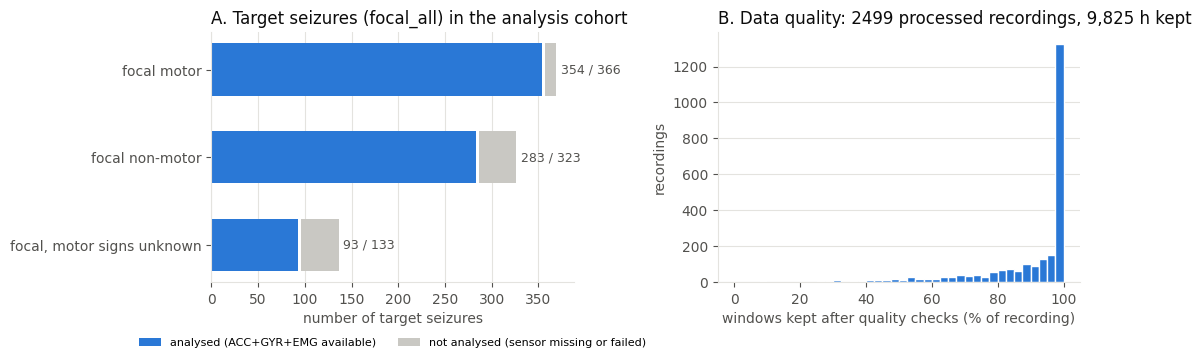

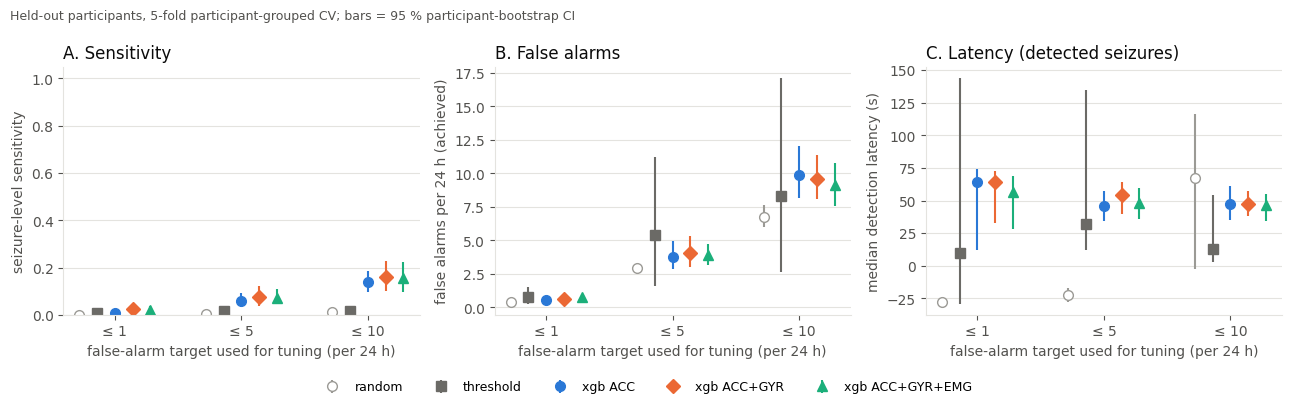

figures saved in /content/drive/MyDrive/bmen600_outputs/figures


In [ ]:
"""Step 5 (NEW): figures required by the rubric, generated directly from the analysis outputs.

Figure 1: dataset and data quality. Figure 2: primary results with 95 % CIs.
Saved as PNG in outputs/figures/.
"""
import matplotlib.pyplot as plt

INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
MODEL_STYLE = {   # colour follows the model, fixed order; baselines are neutral grey
    "random":          dict(color="#9b9a95", marker="o", mfc="white"),
    "threshold":       dict(color="#6b6a66", marker="s", mfc="#6b6a66"),
    "xgb ACC":         dict(color="#2a78d6", marker="o", mfc="#2a78d6"),
    "xgb ACC+GYR":     dict(color="#eb6834", marker="D", mfc="#eb6834"),
    "xgb ACC+GYR+EMG": dict(color="#1baf7a", marker="^", mfc="#1baf7a"),
}
plt.rcParams.update({"axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2,
                     "ytick.color": INK2, "axes.titlecolor": INK, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
                     "grid.linewidth": 0.8, "axes.axisbelow": True, "font.size": 10})

# ---------------------------------------------------------------- Figure 1: dataset
recs_all = pd.read_csv(OUT / "recordings.csv", dtype={"subject": str})
sz_all = pd.read_csv(OUT / "seizures.csv", dtype={"subject": str})
plog = pd.read_csv(OUT / "preprocessing_log.csv", dtype={"subject": str})
ok = plog[plog["error"].isna()] if "error" in plog.columns else plog
cohort = set(ok.loc[ok[SENSOR_FLAGS].all(axis=1), "rec"]) if REQUIRE_ALL_SENSORS else set(ok.rec)

tg = sz_all[sz_all.include].assign(kind=lambda d: d.eventType.map(seizure_kind),
                                   in_cohort=lambda d: d.rec.isin(cohort))
counts = tg.groupby(["kind", "in_cohort"]).size().unstack(fill_value=0).reindex(columns=[True, False], fill_value=0)
counts = counts.loc[counts.sum(axis=1).sort_values().index]

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
y = np.arange(len(counts))
ax[0].barh(y, counts[True], color="#2a78d6", height=0.6, label="analysed (ACC+GYR+EMG available)")
ax[0].barh(y, counts[False], left=counts[True] + counts.values.sum() * 0.004, color="#c9c8c3",
           height=0.6, label="not analysed (sensor missing or failed)")
for i, (a, b) in enumerate(zip(counts[True], counts[False])):
    ax[0].text(a + b + counts.values.sum() * 0.01, i, f"{a} / {a + b}", va="center", color=INK2, fontsize=9)
ax[0].set_yticks(y, counts.index)
ax[0].set_xlabel("number of target seizures")
ax[0].set_title(f"A. Target seizures ({SEIZURE_DEFINITION}) in the analysis cohort", loc="left")
ax[0].legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2, fontsize=8)
ax[0].grid(axis="y", visible=False)

kept_pct = 100 * (1 - (ok.n_bad + ok.n_excluded) / ok.n_windows)
ax[1].hist(kept_pct, bins=np.arange(0, 102.5, 2.5), color="#2a78d6", edgecolor="white", linewidth=1)
ax[1].set_xlabel("windows kept after quality checks (% of recording)")
ax[1].set_ylabel("recordings")
ax[1].set_title(f"B. Data quality: {len(ok)} processed recordings, "
                f"{ok.hours_kept.sum():,.0f} h kept", loc="left")
ax[1].grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig1_dataset_quality.png", dpi=200)
plt.show()

# ---------------------------------------------------------------- Figure 2: results
res = results_summary.copy()
res["model"] = res["model"].astype(str)
panels = [("sensitivity", "sens", "seizure-level sensitivity"),
          ("fa_per_24h", "fa", "false alarms per 24 h (achieved)"),
          ("median_latency_s", "lat", "median detection latency (s)")]
models = [m for m in model_order if m in set(res.model)]
offsets = np.linspace(-0.28, 0.28, len(models))

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax_, (col, pre, ylab) in zip(axes, panels):
    for off, m in zip(offsets, models):
        d = res[res.model == m].sort_values("fa_target")
        x = np.arange(len(d)) + off
        st = MODEL_STYLE.get(m, dict(color=INK2, marker="o", mfc=INK2))
        yerr = np.vstack([d[col] - d[f"{pre}_ci_low"], d[f"{pre}_ci_high"] - d[col]]).clip(min=0)
        ax_.errorbar(x, d[col], yerr=yerr, fmt=st["marker"], color=st["color"], mfc=st["mfc"],
                     ms=7, elinewidth=1.5, capsize=0, lw=0, label=m)
    ax_.set_xticks(np.arange(len(FA_TARGETS)), [f"≤ {t}" for t in FA_TARGETS])
    ax_.set_xlabel("false-alarm target used for tuning (per 24 h)")
    ax_.set_ylabel(ylab)
    ax_.grid(axis="x", visible=False)
axes[0].set_ylim(0, 1.05)
axes[0].set_title("A. Sensitivity", loc="left")
axes[1].set_title("B. False alarms", loc="left")
axes[2].set_title("C. Latency (detected seizures)", loc="left")
handles, labels_ = axes[0].get_legend_handles_labels()
fig.legend(handles, labels_, frameon=False, fontsize=9, loc="lower center", ncol=len(models))
fig.suptitle("Held-out participants, 5-fold participant-grouped CV; bars = 95 % participant-bootstrap CI",
             x=0.01, ha="left", color=INK2, fontsize=9)
fig.tight_layout(rect=(0, 0.07, 1, 1))
fig.savefig(FIG_DIR / "fig2_primary_results.png", dpi=200)
plt.show()
print("figures saved in", FIG_DIR.resolve())


## Before you report the results, check

* **Step 2 prints the movement channel labels** of the first recording. Check that the ACC and GYR channels of the two SensorDots were grouped correctly (`n_acc_sensors` / `n_gyr_sensors` in `preprocessing_log.csv`).
* **Step 2 reports how many recordings are EDF+D or have a signal length that differs from `recordingDuration`.** If there are many, the EDFs contain gaps, and seizure times may not line up with sample counts. Fix that before trusting latency and false-alarm rates.
* The ACC and EMG signals are assumed to share the recording start time (BIDS onsets are relative to the recording start).
* **Seizure definition:** report the one you used (`SEIZURE_DEFINITION`). "Focal non-motor only" is the strictest reading of "non-convulsive", but it has fewer seizures, so the CIs will be wider.